In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("BreastCancer.csv")

print(df.head())
print(df.shape)
print(df.columns)

         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  radius_worst  texture_worst  perimeter_worst  area_wor

In [2]:
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")
df = df.drop_duplicates()

print("Shape after cleaning:", df.shape)

id                         0
diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64
Duplicates: 0
Shape after cleaning: (569, 31)


In [3]:
df["diagnosis"] = df["diagnosis"].map({"B": 0, "M": 1})

print(df["diagnosis"].value_counts())

diagnosis
0    357
1    212
Name: count, dtype: int64


In [4]:
from sklearn.model_selection import train_test_split

X = df.drop("diagnosis", axis=1)
y = df["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (455, 30)
Testing set: (114, 30)


In [5]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

print(X_train[:5])

[[-1.44075296 -0.43531947 -1.36208497 -1.1391179   0.78057331  0.71892128
   2.82313451 -0.11914956  1.09266219  2.45817261 -0.26380039 -0.01605246
  -0.47041357 -0.47476088  0.83836493  3.25102691  8.43893667  3.39198733
   2.62116574  2.06120787 -1.23286131 -0.47630949 -1.24792009 -0.97396758
   0.72289445  1.18673232  4.67282796  0.9320124   2.09724217  1.88645014]
 [ 1.97409619  1.73302577  2.09167167  1.85197292  1.319843    3.42627493
   2.01311199  2.66503199  2.1270036   1.55839569  0.80531919 -0.81268678
   0.75195659  0.87716951 -0.89605315  1.18122247  0.18362761  0.60059598
  -0.31771686  0.52963649  2.17331385  1.3112795   2.08161691  2.1374055
   0.76192793  3.26560084  1.92862053  2.6989469   1.89116053  2.49783848]
 [-1.39998202 -1.24962228 -1.34520926 -1.10978518 -1.33264483 -0.30735463
  -0.36555756 -0.69650228  1.93033305  0.95437877  0.02752055  1.96305996
  -0.12095781 -0.35077918  0.57276579  0.7394992   0.32065553  0.58946222
   2.61504052  0.71892779 -1.29528358

In [6]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

features = [
    "radius_mean",
    "texture_mean",
    "smoothness_mean",
    "concavity_mean"
]

X_reg = df[features]
y_reg = df["area_mean"]

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

In [7]:
simple = LinearRegression()

simple.fit(X_train_reg[["radius_mean"]], y_train_reg)

simple_pred = simple.predict(
    X_test_reg[["radius_mean"]]
)

In [8]:
linear = LinearRegression()

linear.fit(X_train_reg, y_train_reg)

linear_pred = linear.predict(X_test_reg)

In [9]:
poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train_reg)
X_test_poly = poly.transform(X_test_reg)

polynomial = LinearRegression()

polynomial.fit(X_train_poly, y_train_reg)

poly_pred = polynomial.predict(X_test_poly)

In [10]:
ridge = Ridge()
lasso = Lasso()
elastic = ElasticNet()

ridge.fit(X_train_reg, y_train_reg)
lasso.fit(X_train_reg, y_train_reg)
elastic.fit(X_train_reg, y_train_reg)

ElasticNet()

In [11]:
predictions = {
    "Simple Linear": simple_pred,
    "Multiple Linear": linear_pred,
    "Polynomial": poly_pred,
    "Ridge": ridge.predict(X_test_reg),
    "Lasso": lasso.predict(X_test_reg),
    "Elastic Net": elastic.predict(X_test_reg)
}

results = []

for name, predicted in predictions.items():
    mse = mean_squared_error(y_test_reg, predicted)
    r2 = r2_score(y_test_reg, predicted)

    results.append([name, mse, r2])

results_df = pd.DataFrame(
    results,
    columns=["Model", "MSE", "R2"]
)

print(results_df)

             Model          MSE        R2
0    Simple Linear  2169.470364  0.981186
1  Multiple Linear  2241.744465  0.980559
2       Polynomial   260.890544  0.997738
3            Ridge  2197.672901  0.980941
4            Lasso  2172.469519  0.981160
5      Elastic Net  2098.932367  0.981798


Best Model: Polynomial
Best R2: 0.9977375141316008


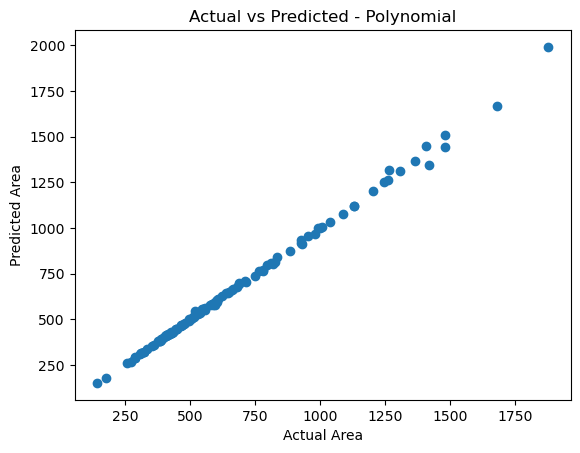

In [12]:
best_row = results_df.loc[results_df["R2"].idxmax()]

best_name = best_row["Model"]
best_pred = predictions[best_name]

print("Best Model:", best_name)
print("Best R2:", best_row["R2"])

plt.scatter(y_test_reg, best_pred)
plt.xlabel("Actual Area")
plt.ylabel("Predicted Area")
plt.title("Actual vs Predicted - " + best_name)
plt.show()

In [13]:
print("Intercept:", polynomial.intercept_)
print("Coefficients:", polynomial.coef_)
print("Features:", poly.get_feature_names_out(features))

Intercept: -65.83727846718921
Coefficients: [ 0.00000000e+00  2.32680002e+00 -2.68373090e-01  1.21626515e+03
 -2.97577093e+01  3.19435388e+00  5.03343494e-02 -6.03524615e+01
  2.49771089e+00 -1.47931244e-02  3.02374405e+00  3.22221851e-01
 -3.65927413e+03  8.05021897e+01 -4.49799294e+00]
Features: ['1' 'radius_mean' 'texture_mean' 'smoothness_mean' 'concavity_mean'
 'radius_mean^2' 'radius_mean texture_mean' 'radius_mean smoothness_mean'
 'radius_mean concavity_mean' 'texture_mean^2'
 'texture_mean smoothness_mean' 'texture_mean concavity_mean'
 'smoothness_mean^2' 'smoothness_mean concavity_mean' 'concavity_mean^2']


In [14]:
five_records = X_test_reg.sample(n=5, random_state=42)

print(five_records)

print("Actual Area:")
print(y_test_reg.loc[five_records.index])

     radius_mean  texture_mean  smoothness_mean  concavity_mean
132        16.16         21.54          0.10080         0.10430
540        11.54         14.44          0.09984         0.06737
104        10.49         19.29          0.09989         0.02995
331        12.98         19.35          0.09579         0.07107
457        13.21         25.25          0.08791         0.02772
Actual Area:
132    809.8
540    402.9
104    336.1
331    514.0
457    537.9
Name: area_mean, dtype: float64


In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

In [16]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Naive Bayes": GaussianNB()
}

classification_results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    classification_results.append(
        [name, accuracy, precision, recall, f1]
    )

classification_df = pd.DataFrame(
    classification_results,
    columns=["Model", "Accuracy", "Precision", "Recall", "F1"]
)

print(classification_df)

                 Model  Accuracy  Precision    Recall        F1
0  Logistic Regression  0.973684   0.976190  0.953488  0.964706
1                  KNN  0.947368   0.930233  0.930233  0.930233
2        Decision Tree  0.947368   0.930233  0.930233  0.930233
3          Naive Bayes  0.964912   0.975610  0.930233  0.952381


In [17]:
best_row = classification_df.loc[
    classification_df["F1"].idxmax()
]

best_classifier = best_row["Model"]
best_model = models[best_classifier]

best_predictions = best_model.predict(X_test)

print("Best Classifier:", best_classifier)
print("Accuracy:", accuracy_score(y_test, best_predictions))
print("Precision:", precision_score(y_test, best_predictions))
print("Recall:", recall_score(y_test, best_predictions))
print("F1:", f1_score(y_test, best_predictions))

Best Classifier: Logistic Regression
Accuracy: 0.9736842105263158
Precision: 0.9761904761904762
Recall: 0.9534883720930233
F1: 0.9647058823529412


Confusion Matrix:
[[70  1]
 [ 2 41]]


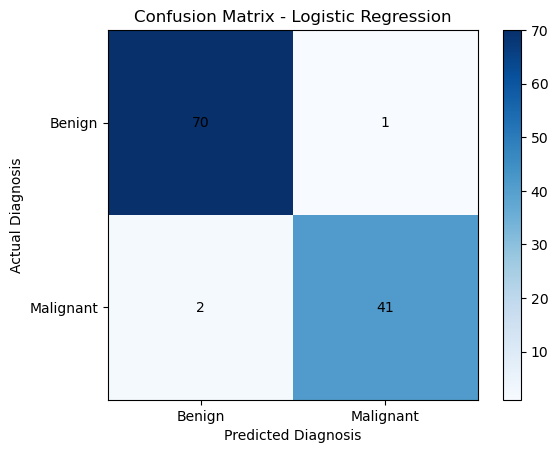

In [18]:
cm = confusion_matrix(y_test, best_predictions)

print("Confusion Matrix:")
print(cm)

plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix - " + best_classifier)
plt.xlabel("Predicted Diagnosis")
plt.ylabel("Actual Diagnosis")

plt.xticks([0, 1], ["Benign", "Malignant"])
plt.yticks([0, 1], ["Benign", "Malignant"])
plt.colorbar()

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.show()

In [19]:
print("Actual Diagnosis Counts:")
print(y_test.value_counts())

print("Predicted Diagnosis Counts:")
print(pd.Series(best_predictions).value_counts())

Actual Diagnosis Counts:
diagnosis
0    71
1    43
Name: count, dtype: int64
Predicted Diagnosis Counts:
0    72
1    42
Name: count, dtype: int64


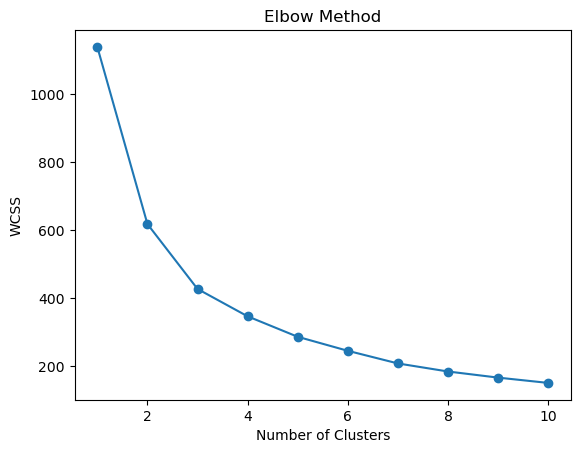

In [20]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

X_cluster = df[["radius_mean", "texture_mean"]]

sc_cluster = StandardScaler()
X_cluster_scaled = sc_cluster.fit_transform(X_cluster)

wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_cluster_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()